# Active Learning & Hard-Negative Mining Across the 387,000 args.me Corpus

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dustinober1/Arg_Me/blob/main/notebooks/11_active_learning_hard_negative_mining.ipynb)

### Executive Summary & Motivation
Random sampling evaluates typical debate arguments, but models fail on the **long tail of complex dialectics** (adversarial quoting, concessions, multi-clause refutations, and rhetorical irony).

This notebook implements an **Active Learning & Hard-Negative Mining Pipeline** that streams across the ~387,000 arguments in `webis/args_me` to systematically extract the hardest dialectical edge cases:
1. **Information-Theoretic Uncertainty Screening**: Computes **Shannon Entropy** $\mathcal{H}(x) = -\sum P(y|x) \log_2 P(y|x)$ and **Margin Sampling** $\mathcal{M}(x) = |P(\text{PRO}) - P(\text{CON})|$ to identify cases where the model experiences maximal doubt.
2. **Error Taxonomy Categorization**: Clusters hard arguments into distinct dialectic failure modes (`adversarial_quoting_trap`, `high_confidence_contradiction`, `concession_complexity`, and `high_entropy_dilemma`).
3. **Curriculum Calibration**: Constructs a high-difficulty benchmark curriculum to stress-test and calibrate stance classifiers against adversarial edge cases.

In [1]:
# 1. Environment Detection, Auto-Cloning & Dependencies
import sys
import os
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if IN_COLAB:
    print("Provisioning dependencies inside Google Colab runtime...")
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn requests matplotlib seaborn tqdm dspy
    if not os.path.exists("Arg_Me") and not os.path.exists("src"):
        print("Cloning Arg_Me repository into Colab...")
        !git clone https://github.com/dustinober1/Arg_Me.git
        %cd Arg_Me
    elif os.path.exists("Arg_Me") and not os.path.exists("src"):
        %cd Arg_Me
    if "/content/Arg_Me" not in sys.path:
        sys.path.insert(0, "/content/Arg_Me")
    print("Colab environment configured! Current working directory:", os.getcwd())
else:
    print("Running in local environment.")

Running in local environment.


In [2]:
# 2. Imports and Ollama Verification
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Ensure project root in sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from src.config import DATA_DIR, ROOT_DIR
from src.active_learning_miner import (
    ActiveLearningHardNegativeMiner,
    compute_uncertainty_metrics,
    categorize_hard_case,
)
from src.dspy_mipro_copro import NimbleStancePredictor

# Verify Ollama
OLLAMA_URL = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/")
try:
    res = requests.get(f"{OLLAMA_URL}/api/tags", timeout=3.0)
    models = [m["name"] for m in res.json().get("models", [])]
    print("Connected to Ollama! Models:", models)
    assert any("nimble" in m for m in models), "Nimble model missing!"
    print("Nimble 9B is ready for uncertainty screening!")
except Exception as e:
    print(f"Ollama status notice: {e}")

/Users/dustinober/Projects/Data_Science/Arg_Me/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Connected to Ollama! Models: ['qwen3.5:2b', 'nimble:latest', 'tev1:4b', 'gemma4:26b-a4b-it-qat']
Nimble 9B is ready for uncertainty screening!


## 1. Uncertainty Metrics & Information Theory
We evaluate how Shannon Entropy $\mathcal{H}$ and Margin $\Delta$ behave across various prediction probabilities:

In [3]:
# 3. Demonstrate Uncertainty Profiling across Synthetic Probabilities
demo_probs = [0.50, 0.55, 0.65, 0.80, 0.95, 0.99]
demo_metrics = []
for p in demo_probs:
    m = compute_uncertainty_metrics(p, 1.0 - p)
    demo_metrics.append({"P(PRO)": p, "P(CON)": round(1.0 - p, 2), **m})

print("=== UNCERTAINTY METRIC COMPARISON ===")
print(pd.DataFrame(demo_metrics).to_string(index=False))

=== UNCERTAINTY METRIC COMPARISON ===
 P(PRO)  P(CON)  entropy  margin  least_confidence
   0.50    0.50   1.0000    0.00              0.50
   0.55    0.45   0.9928    0.10              0.45
   0.65    0.35   0.9341    0.30              0.35
   0.80    0.20   0.7219    0.60              0.20
   0.95    0.05   0.2864    0.90              0.05
   0.99    0.01   0.0808    0.98              0.01


## 2. Active Learning Uncertainty Scan on args.me Arguments
We screen arguments using Bespoke Labs Nimble 9B to calculate entropy, margins, and identify hard cases.

In [4]:
# 4. Run Active Uncertainty Scan on Local Slice
p = DATA_DIR / "args_me_benchmark_5k.parquet"
if not p.exists():
    p = DATA_DIR / "args_me_sample.parquet"

df_sample = pd.read_parquet(p)
print(f"Loaded {len(df_sample):,} arguments for active screening")

miner = ActiveLearningHardNegativeMiner(model_name="nimble")

SCREEN_SIZE = 100  # Adjust as desired (e.g. 50, 100, 250)
hard_cases_df, mining_stats = miner.mine_from_dataframe(df_sample, sample_size=SCREEN_SIZE)

print("\n=== ACTIVE LEARNING MINING STATS ===")
for k, v in mining_stats.items():
    print(f"  {k}: {v}")

# Save Mined Hard Cases Curriculum
curriculum_path = DATA_DIR / "hard_negatives_curriculum.parquet"
hard_cases_df.to_parquet(curriculum_path, index=False)
print(f"\nSaved mined curriculum to: {curriculum_path}")

Loaded 5,000 arguments for active screening


Active Learning Uncertainty Scan: 100%|██████████| 100/100 [00:43<00:00,  2.32it/s]


=== ACTIVE LEARNING MINING STATS ===
  total_screened: 96
  hard_cases_identified: 32
  hard_case_percentage: 33.33
  mean_entropy: 0.3326
  taxonomy_breakdown: {'dialectical_anomaly': 8, 'high_entropy_dilemma': 7, 'standard_example': 6, 'adversarial_quoting_trap': 6, 'high_confidence_contradiction': 4, 'concession_complexity': 1}

Saved mined curriculum to: /Users/dustinober/Projects/Data_Science/Arg_Me/data/hard_negatives_curriculum.parquet


## 3. Taxonomic Analysis of Mined Hard Negatives
We inspect the mined hard negatives and profile the distribution across our dialectic error taxonomy.

=== TOP MINED HARD CASES ===
[1] Category: high_entropy_dilemma | Entropy: 1.000 | Gold: PRO | Pred: PRO
    Topic: Spawn(any kind) vs Goku
    Claim: SPAWN WINS THISSPAWN WINS THISSPAWN WINS THISSPAWN WINS THISHE FORFEITED THIS ROUND BECUASESPAWN WINS THIS WOH...

[2] Category: high_entropy_dilemma | Entropy: 1.000 | Gold: PRO | Pred: PRO
    Topic: Who would win in a fight Master Chief Petty Officer John 117 or C
    Claim: Well con didn't even put up a debate and I gave my side I leave this to the voters sorry for this not being an...

[3] Category: high_entropy_dilemma | Entropy: 0.997 | Gold: CON | Pred: CON
    Topic: Debate.org should have a Prom
    Claim: Sometimes I like to dress up in women's clothing and eat turkey....

[4] Category: high_entropy_dilemma | Entropy: 0.997 | Gold: CON | Pred: CON
    Topic: Illegal Immigration
    Claim: My arguments are extended. I also suggest that I get good conduct on the fact that my opponent has forfeited a...

[5] Category: high_entrop

/var/folders/cl/4_skkqc94qscf3259qh4bpfc0000gn/T/ipykernel_33194/1610789385.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=hard_cases_df, y="taxonomy_category", order=hard_cases_df["taxonomy_category"].value_counts().index, palette="mako")


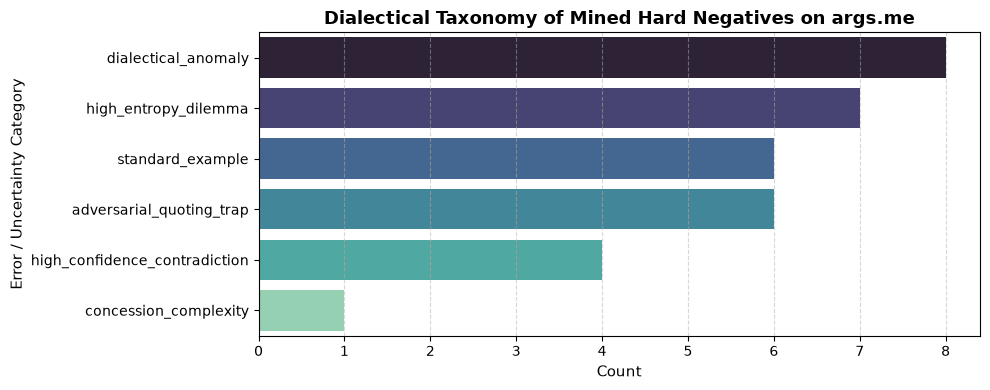

In [5]:
# 5. Inspect Taxonomic Distribution of Hard Negatives
print("=== TOP MINED HARD CASES ===")
for i, (_, row) in enumerate(hard_cases_df.head(5).iterrows(), 1):
    top = row["conclusion"][:65]
    txt = row["premise_text"][:110]
    cat = row["taxonomy_category"]
    ent = row["entropy"]
    gold = row["gold_stance"]
    pred = row["pred_stance"]
    print(f"[{i}] Category: {cat} | Entropy: {ent:.3f} | Gold: {gold} | Pred: {pred}")
    print(f"    Topic: {top}")
    print(f"    Claim: {txt}...")
    print()

# Distribution plot
plt.figure(figsize=(10, 4))
ax = sns.countplot(data=hard_cases_df, y="taxonomy_category", order=hard_cases_df["taxonomy_category"].value_counts().index, palette="mako")
plt.title("Dialectical Taxonomy of Mined Hard Negatives on args.me", fontsize=13, fontweight="bold")
plt.xlabel("Count", fontsize=11)
plt.ylabel("Error / Uncertainty Category", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Streaming Full Corpus Scanner
Below is the streaming ingestion function that enables scanning directly from the Hugging Face Hub across the 387,000 arguments without requiring upfront 850MB local downloads.

In [6]:
# 6. Direct Streaming Hub Demonstration (Optional 20-sample probe)
from src.dataset_loader import get_args_dataset, flatten_argument_record

print("Connecting to Hugging Face Hub streaming iterator...")
ds_stream = get_args_dataset(streaming=True)

stream_records = []
for rec in ds_stream:
    flattened = flatten_argument_record(rec)
    stream_records.extend(flattened)
    if len(stream_records) >= 20:
        break

print(f"Successfully streamed {len(stream_records)} arguments on-the-fly!")
print("Sample Stream Record:")
print("Topic:  ", stream_records[0]["conclusion"])
print("Premise:", stream_records[0]["premise_text"][:100], "...")
print("Stance: ", stream_records[0]["stance"])

Connecting to Hugging Face Hub streaming iterator...
Successfully streamed 20 arguments on-the-fly!
Sample Stream Record:
Topic:   Contraceptive Forms for High School Students
Premise: My opponent forfeited every round. None of my arguments were answered. I don’t like the idea of winn ...
Stance:  CON
